<a href="https://colab.research.google.com/github/Napoleon442/Machine-Learning-Ex.1/blob/main/Exercise_I.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   768.000000  768.000000     768.000000     768.000000  768.000000   
mean      3.845052  120.894531      69.105469      20.536458   79.799479   
std       3.369578   31.972618      19.355807      15.952218  115.244002   
min       0.000000    0.000000       0.000000       0.000000    0.000000   
25%       1.000000   99.000000      62.000000       0.000000    0.000000   
50%       3.000000  117.000000      72.000000      23.000000   30.500000   
75%       6.000000  140.250000      80.000000      32.000000  127.250000   
max      17.000000  199.000000     122.000000      99.000000  846.000000   

              BMI  DiabetesPedigreeFunction         Age     Outcome  
count  768.000000                768.000000  768.000000  768.000000  
mean    31.992578                  0.471876   33.240885    0.348958  
std      7.884160                  0.331329   11.760232    0.476951  
min      0.000000                  

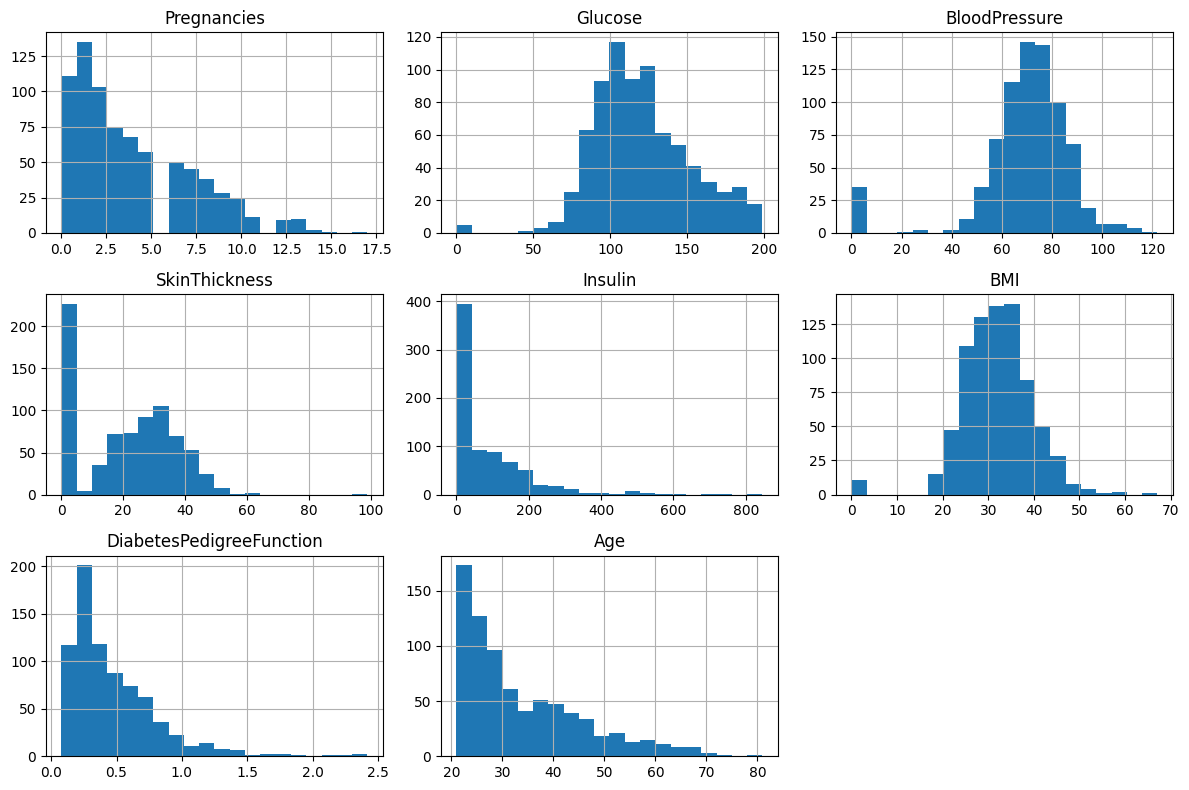

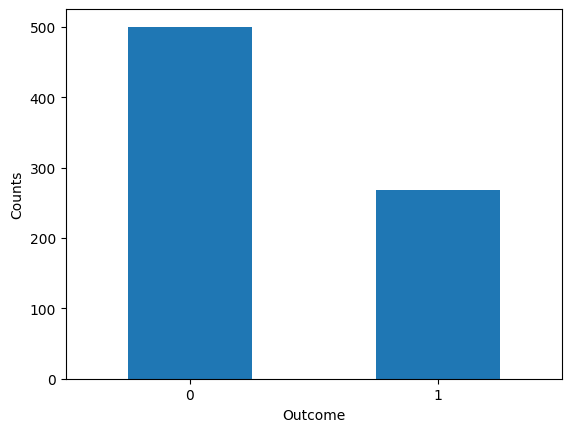

In [ ]:
#PART 1
#1
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler
df = pd.read_csv("diabetes.csv")
print(df.describe())
df.iloc[:, :8].hist(bins=20, figsize=(12,8))
plt.tight_layout()
plt.show()
counts = df["Outcome"].value_counts().sort_index()
counts.plot(kind="bar", rot=0)
plt.xlabel("Outcome")
plt.ylabel("Counts")
plt.show()

#Η πρώτη στήλη αναφέρει τον αριθμό των εγκυμοσύνων και αν υπάρχουν (για άντρες θα είναι 0).
#Η δεύτερη μετράει τα επίπεδα της γλυκόζης. Η τρίτη τη πίεση του κάθε ασθενή.
#Στη τέταρτη στήλη, αναφέρεται το πάχος του δέρματος, καθώς προσφέρει μια γρήγορη εκτίμηση της παχυσαρκίας.
#Ως πέμπτο χαρακτηριστικό ορίζεται η Ινσουλίνη. Μετά, υπολογίζεται το BMI (δείκτης μάζας-ύψους) για αναλυτικότερες ενδείξεις.
#Το έβδομο feature είναι το DiabetesPedigreeFunction, δηλαδή μια μαθηματική συνάρτηση που σχετίζεται με τον γενετικό κίνδυνο ενός ατόμου
#να αποκτήσει διαβήτη (σύμφωνα με το οικογενειακό ιστορικό)
#Η όγδοη στήλη είναι η ηλικία που έχει ο κάθε ασθενής.
#Η τελευταία στήλη είναι το outcome (target) που απαντάει στο αν τελικά ο ασθενής έχει(1) ή δεν έχει (0) διαβήτη.

In [ ]:
#2
X = df.drop(columns="Outcome").to_numpy()
y = df["Outcome"].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
print(X_train.shape)
print(X_test.shape)


(537, 8)
(231, 8)


In [ ]:
#3
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LogisticRegression().fit(X_train_scaled, y_train)

y_train_pred = model.predict(X_train_scaled)
y_test_pred = model.predict(X_test_scaled)
print("Accuracy of Train Set is: ", accuracy_score(y_train, y_train_pred)*100)
print("Accuracy of Test Set is: ", accuracy_score(y_test, y_test_pred)*100)

#Εδώ παρατηρείται ότι το ποσοστό ακρίβειας πρόβλεψης από το Test set των (κανονικοποιημένων) δεδομένων είναι ελαφρώς μεγαλύτερο από
#το Train set (κατα 1,4% περίπου). Το γεγονός ότι τα δύο νούμερα είναι κοντινά θεωρείται πως αποτελεί ένα πειστήριο οτι το fit του μοντέλου LogisticRegression είναι αρκετά καλό.
#Ο λόγος που το Test Set φέρνει μεγαλύτερο ποσοστό ακρίβειας οφείλεται στην ύπαρξη περισσότερων (αναλογικά) "προφανών" προβλέψεων σε σύγκριση με το Train Set.
#Αν αλλαχτεί το random state και γίνει διαχωρισμός άλλων τυχαίων δεδομένων, μπορούμε να παρατηρήσουμε και το αντίστροφο, δηλαδή acc_Train_Set>acc_Test_Set.
#Ωστόσο, και τα δύο νούμερα είναι σε κάθε περίπτωση κοντινά.

Accuracy of Train Set is:  76.35009310986965
Accuracy of Test Set is:  77.92207792207793


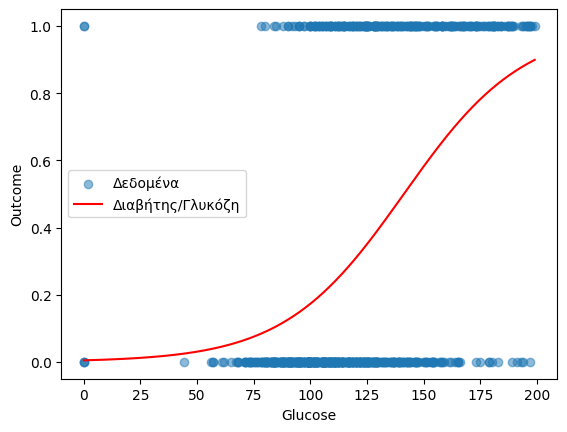

Glucose = 90: πιθανότητα διαβήτη = 0.13
Glucose = 120: πιθανότητα διαβήτη = 0.31
Glucose = 150: πιθανότητα διαβήτη = 0.58
Glucose = 180: πιθανότητα διαβήτη = 0.81


In [ ]:
#4
X_gl = df[["Glucose"]].to_numpy()
y_gl = df["Outcome"].to_numpy()
model_gl = LogisticRegression().fit(X_gl, y_gl)
glucose_range = np.linspace(X_gl.min(), X_gl.max(), 300).reshape(-1, 1)
prob = model_gl.predict_proba(glucose_range)[:, 1]

plt.scatter(X_gl, y_gl, alpha=0.5, label="Δεδομένα")
plt.plot(glucose_range, prob, color= "red", label="Διαβήτης/Γλυκόζη")
plt.xlabel("Glucose")
plt.ylabel("Outcome")
plt.legend()
plt.show()

for g in [90, 120, 150, 180]:
    p = model_gl.predict_proba([[g]])[0, 1]
    print(f"Glucose = {g}: πιθανότητα διαβήτη = {p:.2f}")

#Εφαρμόζοντας Logistic Regression ανάμεσα στη γλυκόζη και το outcome παρατηρούμε μέσα από το διάγραμμα μια τάση περισσότερων αποτελεσμάτων (1)
#με την αύξηση της γλυκόζης. Αντίστοιχα, παίρνοντας ένα μικρό δείγμα πρόβλεψης για μερικές τιμές γλυκόζης, παρατηρούμε την αύξηση της πιθανότητας
#να πάθει ένας ασθενής διαβήτη.

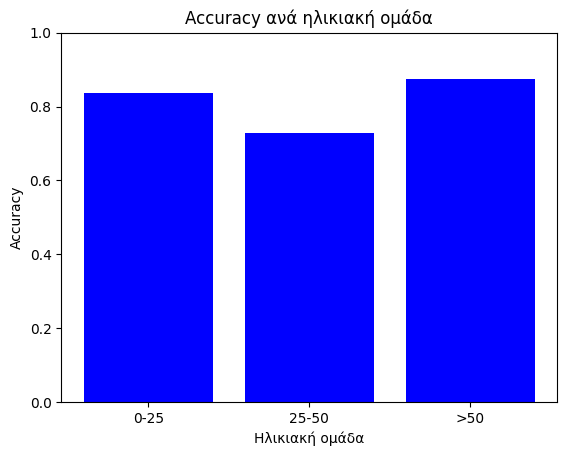

In [ ]:
#5
age_test = X_test[:, 7]

groups = pd.cut(age_test, bins=[0, 25, 50, np.inf],
    labels = ["0-25","25-50", ">50"], right = False)

accuracies = {}
for label in groups:
    mask = groups == label
    accuracies[label]= accuracy_score(y_test[mask], y_test_pred[mask])
    #print(f"{label}: accuracy = {accuracies[label]:.3f} (n={mask.sum()})")

plt.bar(accuracies.keys(), accuracies.values(), color= "blue")
plt.xlabel("Ηλικιακή ομάδα")
plt.ylabel("Accuracy")
plt.title("Accuracy ανά ηλικιακή ομάδα")
plt.ylim(0, 1)
plt.show()

#Ο ταξινομητής δεν δουλεύει το ίδιο καλά για όλες τις ηλικίες. Παρατηρούμε ότι στις ηλικίες 0-25 υπάρχει υψηλό accuracy άνω των 80%. Αυτό σχετίζεται με το γεγονός
#πως υπάρχει ανισσοροπία του ποσοστού του Outcome(0 ή 1), καθώς είναι μεγάλος ο αριθμός των νέων που δεν έχουν διαβήτη(αρα "εύκολες" προβλέψεις για τον ταξινομητή).
#Στις ηλικίες 25-50, η ακρίβεια μειώνεται αισθητά, καθώς είναι πιο δύσκολο για τον ταξινομητή να προβλέψει το πραγματικό outcome (υπάρχει μεγάλη μίξη των features).
#Για τις ηλικίες άνω των 50, η ακρίβεια δεν μπορεί να επαληθεύσει επαρκώς την ποιότητα του μοντέλου μας, διότι είναι πολύ μικρό το εύρος των δεδομένων.

In [ ]:
#6
#Το χειρότερο από όλα (ειδικά στον ιατρικό κλάδο) είναι όταν ένα μοντέλο πρόβλεψης "βγάζει" έναν ασθενή ψευδώς αρνητικό σε μια πάθηση. Έτσι, υπάρχει
#κίνδυνος να επιδεινωθεί η ασθένεια χωρίς να υπάρχει η κατάλληλη ενημέρωση και πρόληψη. Αντίστοιχα, είναι προτιμότερο να προβλέπει λανθασμένα ότι ένας
#ασθενής έχει κάποια πάθηση(έτσι μπορεί να εξεταστεί περαιτέρω).

In [ ]:
#PART 2
#1
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error


X_linear= df[["Pregnancies", "BloodPressure", "BMI", "Age"]].to_numpy()
y_linear= df["Glucose"].to_numpy()

X_linear_train, X_linear_test, y_linear_train, y_linear_test = train_test_split(X_linear, y_linear, test_size=0.3, random_state=0)




In [ ]:
#2
model_linear = LinearRegression().fit(X_linear_train, y_linear_train)
y_linear_pred = model_linear.predict(X_linear_test)

MSE = mean_squared_error(y_linear_test, y_linear_pred)
MAE = mean_absolute_error(y_linear_test, y_linear_pred)
print("MSE: ", round(MSE, 2))
print("MAE: ", round(MAE, 2))

#Το MeanSquaredError υψώνει το σφάλμα στο τετράγωνο. Επομένως, γίνεται πιο δύσκολη η ερμηνεία του. Αντίθετα, το MeanAbsoluteError εξηγεί ότι το μοντέλο
#αστοχεί κατά μέσο όρο περίπου 24 μονάδες γλυκόζης (mg/dL).


MSE:  929.89
MAE:  23.6


In [ ]:
#3
from sklearn.linear_model import RidgeCV, LassoCV

cols = ["Pregnancies", "BloodPressure", "BMI", "Age"]

scaler = StandardScaler().fit(X_linear_train)
Xs_train, Xs_test = scaler.transform(X_linear_train), scaler.transform(X_linear_test)

ols = LinearRegression().fit(Xs_train, y_linear_train)

ridge = RidgeCV(alphas=np.logspace(-3, 3, 50), cv=5).fit(Xs_train, y_linear_train)
lasso = LassoCV(alphas=np.logspace(-3, 1, 50), cv=5, random_state=0).fit(Xs_train, y_linear_train)

print(pd.DataFrame({"OLS": ols.coef_, "Ridge": ridge.coef_, "Lasso": lasso.coef_}, index=cols).round(2))

#Για να συγκρίνουμε σωστά τα δεδομένα των cols μεταξύ τους, πρέπει να τα κανονικοποιήσουμε, διότι έχουν διαφορετικές μονάδες μέτρησης. Εφαρμόζοντας ταυτόχρονα τις 2 γνωστές μεθόδους ομαλοποίησης (Ridge και Lasso),
#παρατηρούμε ότι η ηλικία [Age] είναι ο πιο "σημαντικός" παράγοντας. Αυτό φαίνεται από το γεγονός ότι μια αύξηση κατά 1 τυπική απόκλιση στην ηλικία, αυξάνει τη ποσότητα της γλυκόζης κατά περίπου 9 mg/dL, ενώ για τις άλλες
#μεταβλητές η διαφορά είναι μικρότερη. Επιπλέον, το BMI φαίνεται ότι είναι επίσης αρκετά σημαντικός παράγοντας, ενώ οι εγκυμοσύνες και η πίεση δεν δείχνουν σε πρώτη ματιά να επηρεάζουν άμεσα τη τιμή της γλυκόζης.

                OLS  Ridge  Lasso
Pregnancies   -0.57  -0.07  -0.00
BloodPressure  0.79   1.04   0.50
BMI            7.56   6.92   7.17
Age            9.21   8.21   8.48
